# 07 — Mini benchmark and model-family screening

**Task:** binary classification — Alzheimer prediction

This notebook performs a deliberately compact **model screening** step using only the frozen
`TRAIN` and `VALIDATION` partitions produced by the end-to-end preparation workflow.

The objectives are to:

- compare several classical supervised-learning families;
- evaluate a few manually chosen configurations per family;
- inspect training-versus-validation behavior;
- visualize validation performance;
- select the **top three algorithm families** to carry forward to formal hyperparameter optimization.

This is **not** hyperparameter optimization. There is no `GridSearchCV`, `RandomizedSearchCV`,
Optuna study, or cross-validation search in this notebook.

## Evaluation boundary

The previous end-to-end notebook fitted the data-preparation workflow **only on TRAIN** and exported
frozen, model-ready matrices for TRAIN, VALIDATION, and TEST.

In this screening notebook we use only:

```text
TRAIN      -> fit each candidate model
VALIDATION -> compare candidate models
TEST       -> never loaded
```

Because this is a fixed-holdout screening exercise, using the frozen model-ready TRAIN and VALIDATION
matrices is appropriate. The future hyperparameter-optimization notebook must return to the
**unfitted preparation template** and combine preparation + estimator inside each cross-validation
training fold.

The TEST partition remains protected for final evaluation.

In [1]:
from pathlib import Path
import json
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    average_precision_score,
    log_loss,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
PASTEL_CMAP = sns.light_palette("#6C8EBF", as_cmap=True)
RANDOM_STATE = 42

In [2]:
def find_repo_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / "data").exists() and (candidate / "notebooks").exists():
            return candidate
    raise FileNotFoundError("Repository root could not be located.")

ROOT = find_repo_root()
DATASET = "synthetic_alzheimer"
TASK_DIR = ROOT / "results" / DATASET / "model_screening"
FIG_DIR = TASK_DIR / "figures"
TABLE_DIR = TASK_DIR / "tables"

for path in [TASK_DIR, FIG_DIR, TABLE_DIR]:
    path.mkdir(parents=True, exist_ok=True)

TRAIN_PATH = ROOT / "data" / DATASET / "ml_ready" / "train_ready.csv"
VALIDATION_PATH = ROOT / "data" / DATASET / "ml_ready" / "validation_ready.csv"
MANIFEST_PATH = ROOT / "results" / DATASET / "ml_preparation" / "preparation_manifest.json"
FITTED_PREPARATION_PATH = ROOT / "results" / DATASET / "ml_preparation" / "artifacts" / "preparation_pipeline_fitted.joblib"
TEMPLATE_PREPARATION_PATH = ROOT / "results" / DATASET / "ml_preparation" / "artifacts" / "preparation_pipeline_template.joblib"

for required in [
    TRAIN_PATH,
    VALIDATION_PATH,
    MANIFEST_PATH,
    FITTED_PREPARATION_PATH,
    TEMPLATE_PREPARATION_PATH,
]:
    if not required.exists():
        raise FileNotFoundError(
            f"Missing required artifact: {required}\n"
            "Run notebook 06_end_to_end_ml_preparation.ipynb first."
        )

print("Repository:", ROOT)
print("TRAIN:", TRAIN_PATH.relative_to(ROOT))
print("VALIDATION:", VALIDATION_PATH.relative_to(ROOT))
print("TEST is intentionally not loaded in this notebook.")

Repository: /home/david/Desktop/depto_computacion/ml_2026/demos_machine_learning_2026
TRAIN: data/synthetic_alzheimer/ml_ready/train_ready.csv
VALIDATION: data/synthetic_alzheimer/ml_ready/validation_ready.csv
TEST is intentionally not loaded in this notebook.


## Load the frozen representation

We load the model-ready matrices generated by notebook 06. The saved preparation artifacts are also
loaded to verify provenance and to make the hand-off to the future optimization stage explicit.

The fitted preparation artifact is **not refitted** here. The unfitted template is preserved for the
next stage, where it will be placed inside cross-validation together with each selected estimator.

In [3]:
with MANIFEST_PATH.open("r", encoding="utf-8") as handle:
    manifest = json.load(handle)

fitted_preparation = joblib.load(FITTED_PREPARATION_PATH)
preparation_template = joblib.load(TEMPLATE_PREPARATION_PATH)

train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VALIDATION_PATH)

ID_COL = manifest["identifier"]
TARGET = manifest["target"]
SELECTED_FEATURES = manifest["selected_features"]

expected_columns = [ID_COL, *SELECTED_FEATURES, TARGET]
missing_train = sorted(set(expected_columns) - set(train_df.columns))
missing_val = sorted(set(expected_columns) - set(val_df.columns))

assert not missing_train, f"TRAIN is missing columns: {missing_train}"
assert not missing_val, f"VALIDATION is missing columns: {missing_val}"

X_train = train_df[SELECTED_FEATURES].copy()
y_train = train_df[TARGET].astype(int).copy()
X_val = val_df[SELECTED_FEATURES].copy()
y_val = val_df[TARGET].astype(int).copy()

print(f"TRAIN:      X={X_train.shape}, y={y_train.shape}")
print(f"VALIDATION: X={X_val.shape}, y={y_val.shape}")
print(f"Selected features: {len(SELECTED_FEATURES)}")
print(f"Preparation artifact type: {type(fitted_preparation).__name__}")

TRAIN:      X=(700, 21), y=(700,)
VALIDATION: X=(150, 21), y=(150,)
Selected features: 21
Preparation artifact type: Pipeline


In [4]:
split_summary = pd.DataFrame(
    {
        "partition": ["TRAIN", "VALIDATION"],
        "n": [len(y_train), len(y_val)],
        "positive_n": [int(y_train.sum()), int(y_val.sum())],
        "positive_prevalence_pct": [100 * y_train.mean(), 100 * y_val.mean()],
    }
)
split_summary

,partition,n,positive_n,positive_prevalence_pct
0,TRAIN,700,240,34.285714
1,VALIDATION,150,52,34.666667


## Candidate registry

We intentionally use a **small manual set** of configurations. The goal is not to find the best
hyperparameters. Instead, we ask whether different model families appear promising on the same
frozen representation.

Families included:

- regularized Logistic Regression;
- K-nearest neighbors;
- support-vector machines;
- Random Forest;
- Extra Trees;
- histogram-based gradient boosting.

A `DummyClassifier` is included only as a reference baseline and is excluded from top-three selection.

In [5]:
candidate_specs = [
    {
        "family": "Baseline",
        "config_id": "dummy_prior",
        "is_baseline": True,
        "estimator": DummyClassifier(strategy="prior"),
        "params": {"strategy": "prior"},
    },

    {
        "family": "Logistic Regression",
        "config_id": "logreg_C0.1",
        "is_baseline": False,
        "estimator": LogisticRegression(C=0.1, max_iter=3000, random_state=RANDOM_STATE),
        "params": {"C": 0.1},
    },
    {
        "family": "Logistic Regression",
        "config_id": "logreg_C1",
        "is_baseline": False,
        "estimator": LogisticRegression(C=1.0, max_iter=3000, random_state=RANDOM_STATE),
        "params": {"C": 1.0},
    },
    {
        "family": "Logistic Regression",
        "config_id": "logreg_C10",
        "is_baseline": False,
        "estimator": LogisticRegression(C=10.0, max_iter=3000, random_state=RANDOM_STATE),
        "params": {"C": 10.0},
    },

    {
        "family": "KNN",
        "config_id": "knn_k5_uniform",
        "is_baseline": False,
        "estimator": KNeighborsClassifier(n_neighbors=5, weights="uniform"),
        "params": {"n_neighbors": 5, "weights": "uniform"},
    },
    {
        "family": "KNN",
        "config_id": "knn_k15_distance",
        "is_baseline": False,
        "estimator": KNeighborsClassifier(n_neighbors=15, weights="distance"),
        "params": {"n_neighbors": 15, "weights": "distance"},
    },
    {
        "family": "KNN",
        "config_id": "knn_k25_uniform",
        "is_baseline": False,
        "estimator": KNeighborsClassifier(n_neighbors=25, weights="uniform"),
        "params": {"n_neighbors": 25, "weights": "uniform"},
    },

    {
        "family": "SVM",
        "config_id": "svm_linear_C1",
        "is_baseline": False,
        "estimator": SVC(kernel="linear", C=1.0, probability=True, random_state=RANDOM_STATE),
        "params": {"kernel": "linear", "C": 1.0},
    },
    {
        "family": "SVM",
        "config_id": "svm_rbf_C1",
        "is_baseline": False,
        "estimator": SVC(kernel="rbf", C=1.0, gamma="scale", probability=True, random_state=RANDOM_STATE),
        "params": {"kernel": "rbf", "C": 1.0, "gamma": "scale"},
    },
    {
        "family": "SVM",
        "config_id": "svm_rbf_C10",
        "is_baseline": False,
        "estimator": SVC(kernel="rbf", C=10.0, gamma="scale", probability=True, random_state=RANDOM_STATE),
        "params": {"kernel": "rbf", "C": 10.0, "gamma": "scale"},
    },

    {
        "family": "Random Forest",
        "config_id": "rf_default",
        "is_baseline": False,
        "estimator": RandomForestClassifier(
            n_estimators=300,
            max_depth=None,
            min_samples_leaf=1,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "params": {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 1},
    },
    {
        "family": "Random Forest",
        "config_id": "rf_depth8_leaf2",
        "is_baseline": False,
        "estimator": RandomForestClassifier(
            n_estimators=300,
            max_depth=8,
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "params": {"n_estimators": 300, "max_depth": 8, "min_samples_leaf": 2},
    },
    {
        "family": "Random Forest",
        "config_id": "rf_depth5_leaf4",
        "is_baseline": False,
        "estimator": RandomForestClassifier(
            n_estimators=300,
            max_depth=5,
            min_samples_leaf=4,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "params": {"n_estimators": 300, "max_depth": 5, "min_samples_leaf": 4},
    },

    {
        "family": "Extra Trees",
        "config_id": "et_default",
        "is_baseline": False,
        "estimator": ExtraTreesClassifier(
            n_estimators=300,
            max_depth=None,
            min_samples_leaf=1,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "params": {"n_estimators": 300, "max_depth": None, "min_samples_leaf": 1},
    },
    {
        "family": "Extra Trees",
        "config_id": "et_depth8_leaf2",
        "is_baseline": False,
        "estimator": ExtraTreesClassifier(
            n_estimators=300,
            max_depth=8,
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "params": {"n_estimators": 300, "max_depth": 8, "min_samples_leaf": 2},
    },
    {
        "family": "Extra Trees",
        "config_id": "et_depth5_leaf4",
        "is_baseline": False,
        "estimator": ExtraTreesClassifier(
            n_estimators=300,
            max_depth=5,
            min_samples_leaf=4,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        "params": {"n_estimators": 300, "max_depth": 5, "min_samples_leaf": 4},
    },

    {
        "family": "HistGradientBoosting",
        "config_id": "hgb_lr0.05_leaf15",
        "is_baseline": False,
        "estimator": HistGradientBoostingClassifier(
            learning_rate=0.05,
            max_iter=200,
            max_leaf_nodes=15,
            l2_regularization=0.0,
            random_state=RANDOM_STATE,
        ),
        "params": {"learning_rate": 0.05, "max_iter": 200, "max_leaf_nodes": 15, "l2_regularization": 0.0},
    },
    {
        "family": "HistGradientBoosting",
        "config_id": "hgb_lr0.10_leaf31",
        "is_baseline": False,
        "estimator": HistGradientBoostingClassifier(
            learning_rate=0.10,
            max_iter=200,
            max_leaf_nodes=31,
            l2_regularization=0.0,
            random_state=RANDOM_STATE,
        ),
        "params": {"learning_rate": 0.10, "max_iter": 200, "max_leaf_nodes": 31, "l2_regularization": 0.0},
    },
    {
        "family": "HistGradientBoosting",
        "config_id": "hgb_lr0.05_leaf31_l2",
        "is_baseline": False,
        "estimator": HistGradientBoostingClassifier(
            learning_rate=0.05,
            max_iter=250,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            random_state=RANDOM_STATE,
        ),
        "params": {"learning_rate": 0.05, "max_iter": 250, "max_leaf_nodes": 31, "l2_regularization": 1.0},
    },
]

candidate_table = pd.DataFrame(
    [
        {
            "family": item["family"],
            "config_id": item["config_id"],
            "is_baseline": item["is_baseline"],
            "params": json.dumps(item["params"], sort_keys=True),
        }
        for item in candidate_specs
    ]
)
candidate_table

,family,config_id,is_baseline,params
0,Baseline,dummy_prior,True,"{""strategy"": ""prior""}"
1,Logistic Regression,logreg_C0.1,False,"{""C"": 0.1}"
2,Logistic Regression,logreg_C1,False,"{""C"": 1.0}"
3,Logistic Regression,logreg_C10,False,"{""C"": 10.0}"
4,KNN,knn_k5_uniform,False,"{""n_neighbors"": 5, ""weights"": ""uniform""}"
5,KNN,knn_k15_distance,False,"{""n_neighbors"": 15, ""weights"": ""distance""}"
6,KNN,knn_k25_uniform,False,"{""n_neighbors"": 25, ""weights"": ""uniform""}"
7,SVM,svm_linear_C1,False,"{""C"": 1.0, ""kernel"": ""linear""}"
8,SVM,svm_rbf_C1,False,"{""C"": 1.0, ""gamma"": ""scale"", ""kernel"": ""rbf""}"
9,SVM,svm_rbf_C10,False,"{""C"": 10.0, ""gamma"": ""scale"", ""kernel"": ""rbf""}"


## Metrics and screening rule

The **primary screening metric is MCC** because it incorporates all cells of the binary confusion
matrix and remains informative when class proportions are not perfectly balanced.

Secondary validation metrics:

- balanced accuracy;
- F1;
- ROC-AUC;
- average precision;
- log loss.

TRAIN metrics are retained to inspect possible overfitting, but they **do not determine the winner**.

Family-level selection follows:

1. keep the best manual configuration within each algorithm family by validation MCC;
2. break close ties using balanced accuracy and ROC-AUC;
3. inspect the TRAIN–VALIDATION MCC gap;
4. carry the top three non-baseline families forward.

In [6]:
def get_positive_probability(model, X):
    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(X)
        classes = list(model.classes_)
        positive_idx = classes.index(1)
        return proba[:, positive_idx]
    raise TypeError(f"{type(model).__name__} does not provide predict_proba().")

def classification_metrics(y_true, y_pred, y_prob):
    eps = 1e-12
    y_prob = np.clip(np.asarray(y_prob), eps, 1 - eps)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "mcc": matthews_corrcoef(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "average_precision": average_precision_score(y_true, y_prob),
        "log_loss": log_loss(y_true, np.column_stack([1 - y_prob, y_prob]), labels=[0, 1]),
    }

results = []
fitted_by_config = {}

for spec in candidate_specs:
    model = clone(spec["estimator"])

    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)
    train_prob = get_positive_probability(model, X_train)
    val_prob = get_positive_probability(model, X_val)

    train_metrics = classification_metrics(y_train, train_pred, train_prob)
    val_metrics = classification_metrics(y_val, val_pred, val_prob)

    row = {
        "family": spec["family"],
        "config_id": spec["config_id"],
        "is_baseline": spec["is_baseline"],
        "params": json.dumps(spec["params"], sort_keys=True),
        "fit_seconds": fit_seconds,
    }
    row.update({f"train_{k}": v for k, v in train_metrics.items()})
    row.update({f"val_{k}": v for k, v in val_metrics.items()})
    row["mcc_gap_train_minus_val"] = row["train_mcc"] - row["val_mcc"]
    results.append(row)
    fitted_by_config[spec["config_id"]] = model

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    ["val_mcc", "val_balanced_accuracy", "val_roc_auc"],
    ascending=[False, False, False],
).reset_index(drop=True)

results_df.to_csv(TABLE_DIR / "candidate_results.csv", index=False)
results_df.head(10)

,family,config_id,is_baseline,params,fit_seconds,train_accuracy,train_balanced_accuracy,train_f1,train_mcc,train_roc_auc,train_average_precision,train_log_loss,val_accuracy,val_balanced_accuracy,val_f1,val_mcc,val_roc_auc,val_average_precision,val_log_loss,mcc_gap_train_minus_val
0,SVM,svm_linear_C1,False,"{""C"": 1.0, ""kernel"": ""linear""}",0.072422,0.774286,0.724638,0.632558,0.479551,0.807002,0.688998,0.500528,0.713333,0.667779,0.556701,0.348482,0.740188,0.622716,0.558214,0.131069
1,Logistic Regression,logreg_C0.1,False,"{""C"": 0.1}",0.007225,0.778571,0.723913,0.630072,0.487246,0.808216,0.683747,0.500942,0.713333,0.663265,0.547368,0.343647,0.736068,0.615894,0.561545,0.143599
2,Logistic Regression,logreg_C1,False,"{""C"": 1.0}",0.010114,0.782857,0.731159,0.641509,0.498531,0.810870,0.692553,0.495525,0.700000,0.653061,0.536082,0.317914,0.736264,0.615471,0.568566,0.180618
3,Logistic Regression,logreg_C10,False,"{""C"": 10.0}",0.008860,0.785714,0.736322,0.649533,0.506181,0.810661,0.693281,0.495317,0.700000,0.653061,0.536082,0.317914,0.734498,0.613550,0.571597,0.188267
4,HistGradientBoosting,hgb_lr0.05_leaf15,False,"{""l2_regularization"": 0.0, ""learning_rate"": 0....",0.171635,0.975714,0.965580,0.963441,0.946391,0.999049,0.998288,0.171095,0.693333,0.652473,0.540000,0.311111,0.711342,0.573406,0.646088,0.635280
5,SVM,svm_rbf_C10,False,"{""C"": 10.0, ""gamma"": ""scale"", ""kernel"": ""rbf""}",0.128252,0.941429,0.916576,0.907449,0.871531,0.972274,0.972432,0.386743,0.693333,0.647959,0.530612,0.305415,0.673764,0.532527,0.603326,0.566115
6,Random Forest,rf_default,False,"{""max_depth"": null, ""min_samples_leaf"": 1, ""n_...",0.365105,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.146925,0.686667,0.651884,0.543689,0.305178,0.712520,0.572569,0.593973,0.694822
7,SVM,svm_rbf_C1,False,"{""C"": 1.0, ""gamma"": ""scale"", ""kernel"": ""rbf""}",0.081817,0.830000,0.783967,0.720000,0.611355,0.874393,0.837827,0.437736,0.693333,0.643446,0.520833,0.299884,0.720467,0.623532,0.572852,0.311471
8,HistGradientBoosting,hgb_lr0.10_leaf31,False,"{""l2_regularization"": 0.0, ""learning_rate"": 0....",0.264312,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.016396,0.686667,0.642857,0.525253,0.293143,0.695251,0.557136,0.953343,0.706857
9,Extra Trees,et_depth8_leaf2,False,"{""max_depth"": 8, ""min_samples_leaf"": 2, ""n_est...",0.250695,0.880000,0.825996,0.788945,0.740285,0.935199,0.919468,0.380140,0.693333,0.634419,0.500000,0.289321,0.727630,0.604007,0.569041,0.450965


## Performance exploration

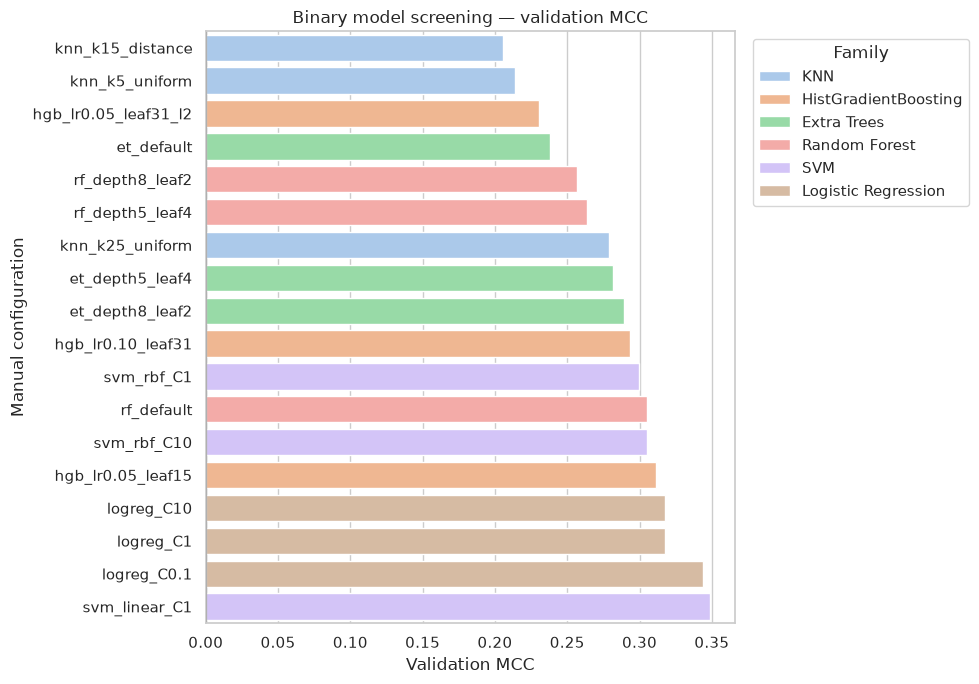

In [7]:
plot_df = results_df.loc[~results_df["is_baseline"]].copy()
plot_df = plot_df.sort_values("val_mcc", ascending=True)

plt.figure(figsize=(10, 7))
sns.barplot(data=plot_df, x="val_mcc", y="config_id", hue="family", dodge=False, palette="pastel")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Validation MCC")
plt.ylabel("Manual configuration")
plt.title("Binary model screening — validation MCC")
plt.legend(title="Family", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_candidate_validation_mcc.png", dpi=160, bbox_inches="tight")
plt.show()

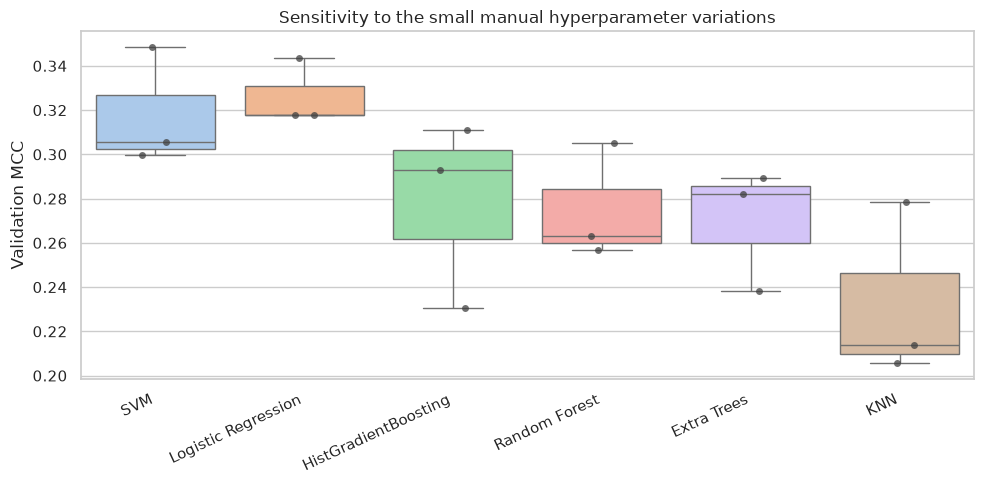

In [8]:
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=results_df.loc[~results_df["is_baseline"]],
    x="family",
    y="val_mcc",
    palette="pastel",
    showfliers=False,
)
sns.stripplot(
    data=results_df.loc[~results_df["is_baseline"]],
    x="family",
    y="val_mcc",
    color="0.25",
    size=5,
    alpha=0.75,
)
plt.xticks(rotation=25, ha="right")
plt.ylabel("Validation MCC")
plt.xlabel("")
plt.title("Sensitivity to the small manual hyperparameter variations")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_family_validation_mcc_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

In [9]:
nonbaseline = results_df.loc[~results_df["is_baseline"]].copy()
family_best = (
    nonbaseline.sort_values(
        ["val_mcc", "val_balanced_accuracy", "val_roc_auc", "mcc_gap_train_minus_val"],
        ascending=[False, False, False, True],
    )
    .groupby("family", as_index=False, sort=False)
    .first()
)

family_best = family_best.sort_values(
    ["val_mcc", "val_balanced_accuracy", "val_roc_auc", "mcc_gap_train_minus_val"],
    ascending=[False, False, False, True],
).reset_index(drop=True)
family_best["family_rank"] = np.arange(1, len(family_best) + 1)

family_best.to_csv(TABLE_DIR / "family_best_results.csv", index=False)
family_best[
    [
        "family_rank",
        "family",
        "config_id",
        "val_mcc",
        "val_balanced_accuracy",
        "val_f1",
        "val_roc_auc",
        "val_average_precision",
        "mcc_gap_train_minus_val",
    ]
]

,family_rank,family,config_id,val_mcc,val_balanced_accuracy,val_f1,val_roc_auc,val_average_precision,mcc_gap_train_minus_val
0,1,SVM,svm_linear_C1,0.348482,0.667779,0.556701,0.740188,0.622716,0.131069
1,2,Logistic Regression,logreg_C0.1,0.343647,0.663265,0.547368,0.736068,0.615894,0.143599
2,3,HistGradientBoosting,hgb_lr0.05_leaf15,0.311111,0.652473,0.540000,0.711342,0.573406,0.635280
3,4,Random Forest,rf_default,0.305178,0.651884,0.543689,0.712520,0.572569,0.694822
4,5,Extra Trees,et_depth8_leaf2,0.289321,0.634419,0.500000,0.727630,0.604007,0.450965
5,6,KNN,knn_k25_uniform,0.278571,0.612441,0.430380,0.696723,0.549573,0.072492


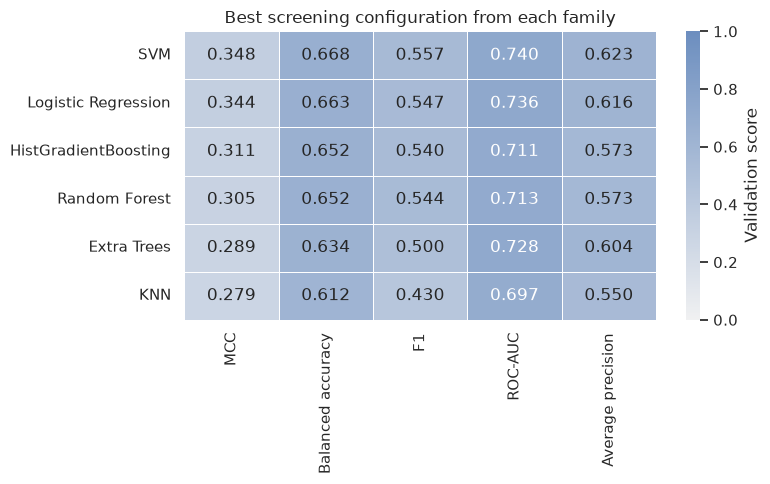

In [10]:
heatmap_metrics = [
    "val_mcc",
    "val_balanced_accuracy",
    "val_f1",
    "val_roc_auc",
    "val_average_precision",
]
heatmap_df = family_best.set_index("family")[heatmap_metrics].copy()
heatmap_df.columns = [
    "MCC",
    "Balanced accuracy",
    "F1",
    "ROC-AUC",
    "Average precision",
]

plt.figure(figsize=(8, 5))
sns.heatmap(
    heatmap_df,
    annot=True,
    fmt=".3f",
    cmap=PASTEL_CMAP,
    vmin=0,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Validation score"},
)
plt.title("Best screening configuration from each family")
plt.ylabel("")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_family_best_metric_heatmap.png", dpi=160, bbox_inches="tight")
plt.show()

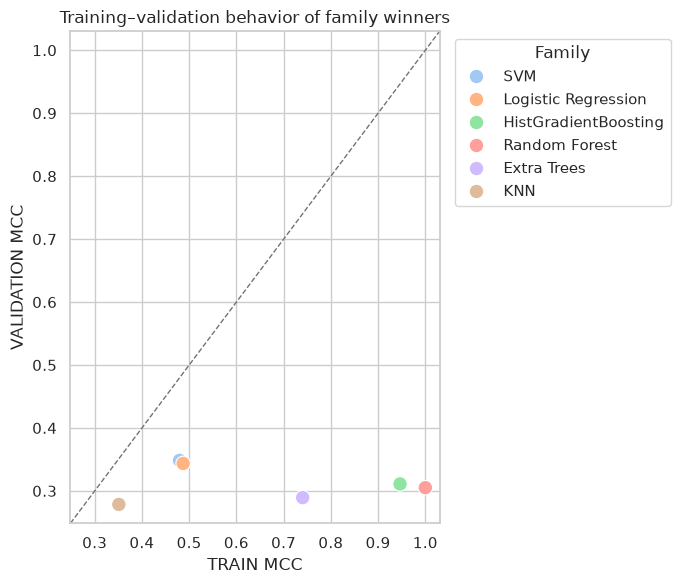

In [11]:
plt.figure(figsize=(7, 6))
sns.scatterplot(
    data=family_best,
    x="train_mcc",
    y="val_mcc",
    hue="family",
    s=110,
    palette="pastel",
)
limits = [
    min(family_best["train_mcc"].min(), family_best["val_mcc"].min()) - 0.03,
    max(family_best["train_mcc"].max(), family_best["val_mcc"].max()) + 0.03,
]
plt.plot(limits, limits, linestyle="--", linewidth=1, color="0.45")
plt.xlim(limits)
plt.ylim(limits)
plt.xlabel("TRAIN MCC")
plt.ylabel("VALIDATION MCC")
plt.title("Training–validation behavior of family winners")
plt.legend(title="Family", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_train_validation_mcc.png", dpi=160, bbox_inches="tight")
plt.show()

## Select the top three algorithm families

The screening winner for a family is only a **reference configuration**. It is not treated as an
optimized model. The next stage will define a proper search space around each selected family and
optimize it using TRAIN-only cross-validation with the unfitted preparation template.

In [12]:
top3 = family_best.head(3).copy()
top3["selected_for_optimization"] = True
top3.to_csv(TABLE_DIR / "top3_algorithms.csv", index=False)

top3[
    [
        "family_rank",
        "family",
        "config_id",
        "params",
        "val_mcc",
        "val_balanced_accuracy",
        "val_roc_auc",
        "mcc_gap_train_minus_val",
    ]
]

,family_rank,family,config_id,params,val_mcc,val_balanced_accuracy,val_roc_auc,mcc_gap_train_minus_val
0,1,SVM,svm_linear_C1,"{""C"": 1.0, ""kernel"": ""linear""}",0.348482,0.667779,0.740188,0.131069
1,2,Logistic Regression,logreg_C0.1,"{""C"": 0.1}",0.343647,0.663265,0.736068,0.143599
2,3,HistGradientBoosting,hgb_lr0.05_leaf15,"{""l2_regularization"": 0.0, ""learning_rate"": 0....",0.311111,0.652473,0.711342,0.635280


In [13]:
top3_records = []
for _, row in top3.iterrows():
    top3_records.append(
        {
            "rank": int(row["family_rank"]),
            "family": row["family"],
            "screening_config_id": row["config_id"],
            "screening_params": json.loads(row["params"]),
            "validation_mcc": float(row["val_mcc"]),
            "validation_balanced_accuracy": float(row["val_balanced_accuracy"]),
            "validation_roc_auc": float(row["val_roc_auc"]),
            "train_validation_mcc_gap": float(row["mcc_gap_train_minus_val"]),
        }
    )

selection_manifest = {
    "dataset": DATASET,
    "task_type": "binary_classification",
    "screening_scope": "fixed TRAIN/VALIDATION holdout only",
    "test_used": False,
    "primary_metric": "MCC",
    "selection_level": "algorithm family",
    "n_candidate_configurations": int(len(results_df)),
    "n_nonbaseline_families": int(len(family_best)),
    "top3": top3_records,
    "next_step": (
        "Optimize these three families using TRAIN-only cross-validation. "
        "Combine each estimator with preparation_pipeline_template.joblib inside CV. "
        "Keep TEST protected."
    ),
}

with (TASK_DIR / "top3_selection_manifest.json").open("w", encoding="utf-8") as handle:
    json.dump(selection_manifest, handle, indent=2)

print(json.dumps(selection_manifest, indent=2))

{
  "dataset": "synthetic_alzheimer",
  "task_type": "binary_classification",
  "screening_scope": "fixed TRAIN/VALIDATION holdout only",
  "test_used": false,
  "primary_metric": "MCC",
  "selection_level": "algorithm family",
  "n_candidate_configurations": 19,
  "n_nonbaseline_families": 6,
  "top3": [
    {
      "rank": 1,
      "family": "SVM",
      "screening_config_id": "svm_linear_C1",
      "screening_params": {
        "C": 1.0,
        "kernel": "linear"
      },
      "validation_mcc": 0.3484821153303148,
      "validation_balanced_accuracy": 0.667778649921507,
      "validation_roc_auc": 0.7401883830455259,
      "train_validation_mcc_gap": 0.13106938190826278
    },
    {
      "rank": 2,
      "family": "Logistic Regression",
      "screening_config_id": "logreg_C0.1",
      "screening_params": {
        "C": 0.1
      },
      "validation_mcc": 0.3436469515259675,
      "validation_balanced_accuracy": 0.6632653061224489,
      "validation_roc_auc": 0.7360675039246467,

## Validation behavior of the selected families

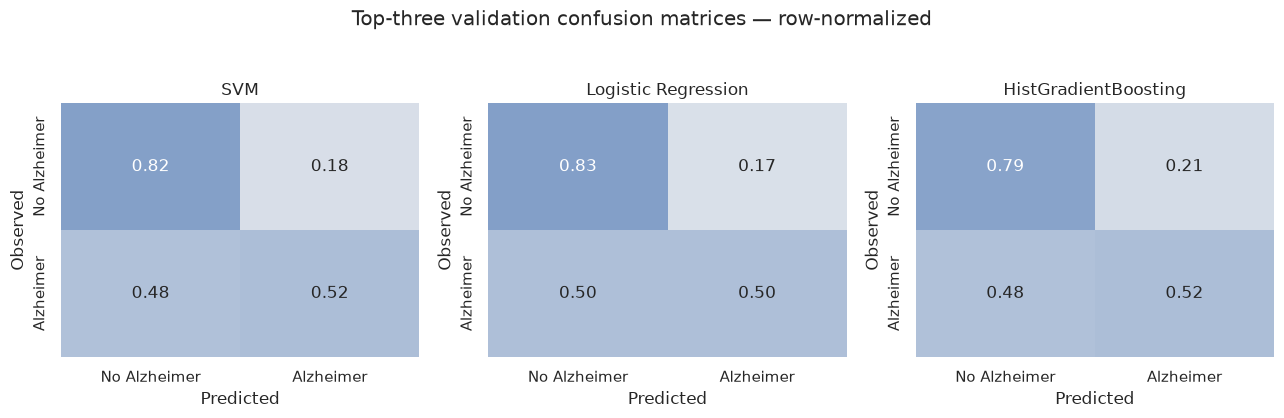

In [14]:
top3_models = {}
for _, row in top3.iterrows():
    config_id = row["config_id"]
    top3_models[row["family"]] = fitted_by_config[config_id]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (family, model) in zip(axes, top3_models.items()):
    pred = model.predict(X_val)
    cm = confusion_matrix(y_val, pred, labels=[0, 1], normalize="true")
    sns.heatmap(
        cm,
        annot=True,
        fmt=".2f",
        cmap=PASTEL_CMAP,
        vmin=0,
        vmax=1,
        cbar=False,
        xticklabels=["No Alzheimer", "Alzheimer"],
        yticklabels=["No Alzheimer", "Alzheimer"],
        ax=ax,
    )
    ax.set_title(family)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Observed")

fig.suptitle("Top-three validation confusion matrices — row-normalized", y=1.04)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_top3_confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()

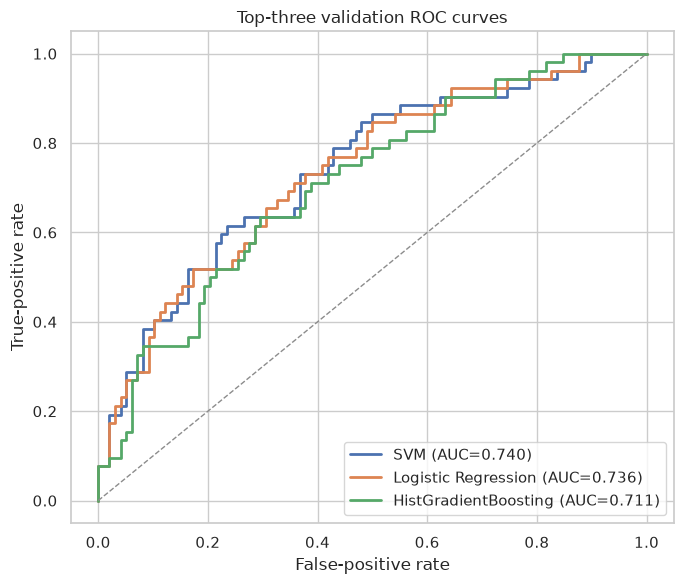

In [15]:
plt.figure(figsize=(7, 6))
for family, model in top3_models.items():
    prob = get_positive_probability(model, X_val)
    fpr, tpr, _ = roc_curve(y_val, prob)
    auc = roc_auc_score(y_val, prob)
    plt.plot(fpr, tpr, linewidth=2, label=f"{family} (AUC={auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="0.55", linewidth=1)
plt.xlabel("False-positive rate")
plt.ylabel("True-positive rate")
plt.title("Top-three validation ROC curves")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "06_top3_roc_curves.png", dpi=160, bbox_inches="tight")
plt.show()

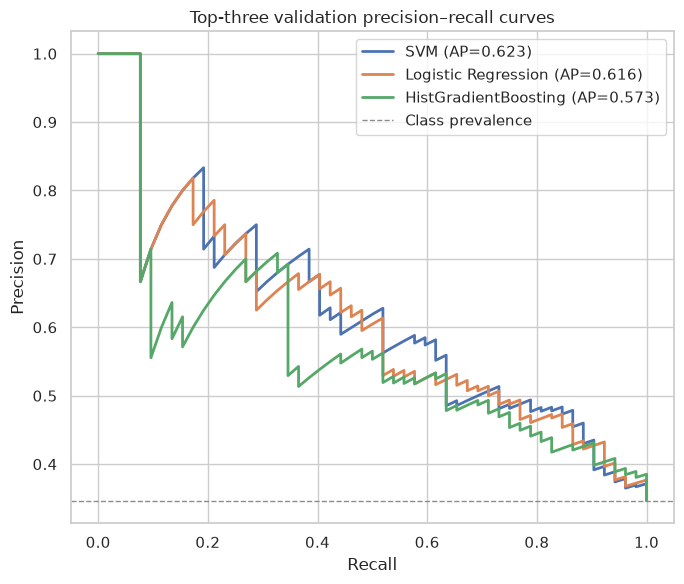

In [16]:
plt.figure(figsize=(7, 6))
baseline_prevalence = y_val.mean()

for family, model in top3_models.items():
    prob = get_positive_probability(model, X_val)
    precision, recall, _ = precision_recall_curve(y_val, prob)
    ap = average_precision_score(y_val, prob)
    plt.plot(recall, precision, linewidth=2, label=f"{family} (AP={ap:.3f})")

plt.axhline(baseline_prevalence, linestyle="--", color="0.55", linewidth=1, label="Class prevalence")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Top-three validation precision–recall curves")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "07_top3_precision_recall_curves.png", dpi=160, bbox_inches="tight")
plt.show()

## Interpretation and hand-off

This notebook answers only:

> Which classical model families look sufficiently promising to justify formal optimization?

It does **not** establish the final model and it does not estimate final generalization.

The next optimization stage should:

1. read `top3_selection_manifest.json`;
2. instantiate those three model families;
3. define explicit hyperparameter search spaces;
4. load `preparation_pipeline_template.joblib`;
5. place preparation and estimator in the same scikit-learn pipeline;
6. optimize using cross-validation **inside TRAIN**;
7. use VALIDATION for the predefined post-optimization comparison if desired;
8. leave TEST untouched until the workflow is frozen.

In [17]:
print("Screening complete.")
print("Top three families:")
for record in top3_records:
    print(
        f"  {record['rank']}. {record['family']} "
        f"(validation MCC={record['validation_mcc']:.3f})"
    )
print("\nTEST was not loaded or evaluated.")
print("Results:", TASK_DIR.relative_to(ROOT))

Screening complete.
Top three families:
  1. SVM (validation MCC=0.348)
  2. Logistic Regression (validation MCC=0.344)
  3. HistGradientBoosting (validation MCC=0.311)

TEST was not loaded or evaluated.
Results: results/synthetic_alzheimer/model_screening
